## Load data set

In [4]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3})

annual = pd.read_csv("cleaned_annual_interest_rate.csv")
annual["range"] = annual["mortgage_rate_max"] - annual["mortgage_rate_min"]   # within-year spread (pp)
annual["pct_change"] = annual["mortgage_rate_mean"].pct_change() * 100

## Overview and data quality

In [9]:
print("Shape:", annual.shape)
print("Years:", annual["year"].min(), "to", annual["year"].max(), "| duplicated years:", annual["year"].duplicated().sum())
print("\nMissing values:\n", annual.isna().sum()[lambda s: s > 0].to_string())
annual.dtypes.to_frame("dtype").T

Shape: (10, 10)
Years: 2015 to 2024 | duplicated years: 0

Missing values:
 mortgage_rate_change    1
pct_change              1


,year,mortgage_rate_mean,mortgage_rate_median,mortgage_rate_min,mortgage_rate_max,n_weeks,mortgage_rate_yearend,mortgage_rate_change,range,pct_change
dtype,int64,float64,float64,float64,float64,int64,float64,float64,float64,float64


Only `mortgage_rate_change` has a missing value, for 2015, since the data has no 2014 value to difference against. Every year is present exactly once.

In [12]:
annual[["mortgage_rate_mean", "mortgage_rate_median", "mortgage_rate_min", "mortgage_rate_max", "mortgage_rate_yearend", "mortgage_rate_change"]].describe().round(3)

,mortgage_rate_mean,mortgage_rate_median,mortgage_rate_min,mortgage_rate_max,mortgage_rate_yearend,mortgage_rate_change
count,10.000,10.000,10.000,10.000,10.000,9.000
mean,4.492,4.458,3.892,5.115,4.627,0.319
std,1.374,1.380,1.231,1.629,1.487,1.028
min,2.958,2.975,2.650,3.180,2.670,-0.824
25%,3.703,3.641,3.268,4.142,3.802,-0.197
50%,3.963,3.902,3.540,4.415,4.165,-0.086
75%,5.144,5.112,3.908,6.545,5.952,0.555
max,6.807,6.775,6.090,7.790,6.850,2.386


The annual mean ranged from 2.96% (2021) to 6.81% (2023), with an average of 4.49% across the 10 years.

## Trend over time

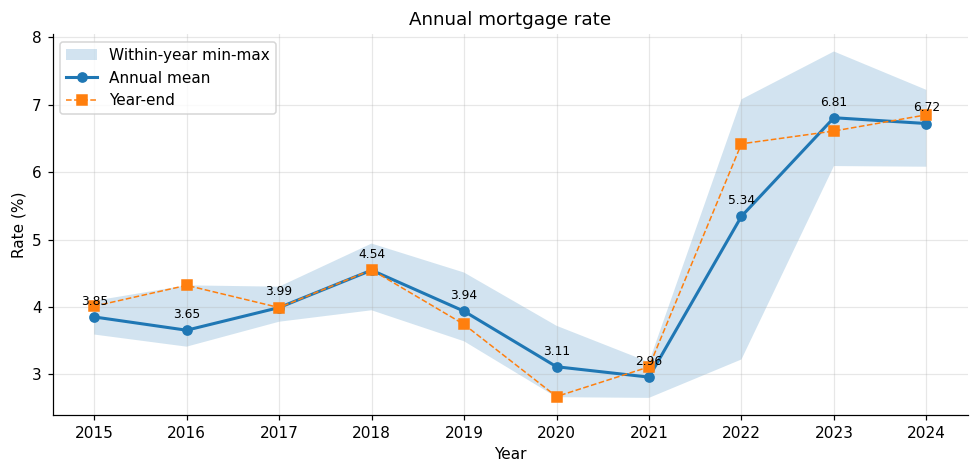

In [15]:
fig, ax = plt.subplots(figsize=(9, 4.4))
ax.fill_between(annual["year"], annual["mortgage_rate_min"], annual["mortgage_rate_max"], alpha=0.2, label="Within-year min-max")
ax.plot(annual["year"], annual["mortgage_rate_mean"], marker="o", lw=2, label="Annual mean")
ax.plot(annual["year"], annual["mortgage_rate_yearend"], marker="s", ls="--", lw=1, label="Year-end")
for _, r in annual.iterrows():
    ax.annotate(f"{r['mortgage_rate_mean']:.2f}", (r["year"], r["mortgage_rate_mean"]), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=8)
ax.set(title="Annual mortgage rate", xlabel="Year", ylabel="Rate (%)"); ax.set_xticks(annual["year"]); ax.legend(loc="upper left")
plt.tight_layout(); plt.show()

## Year-over-year change

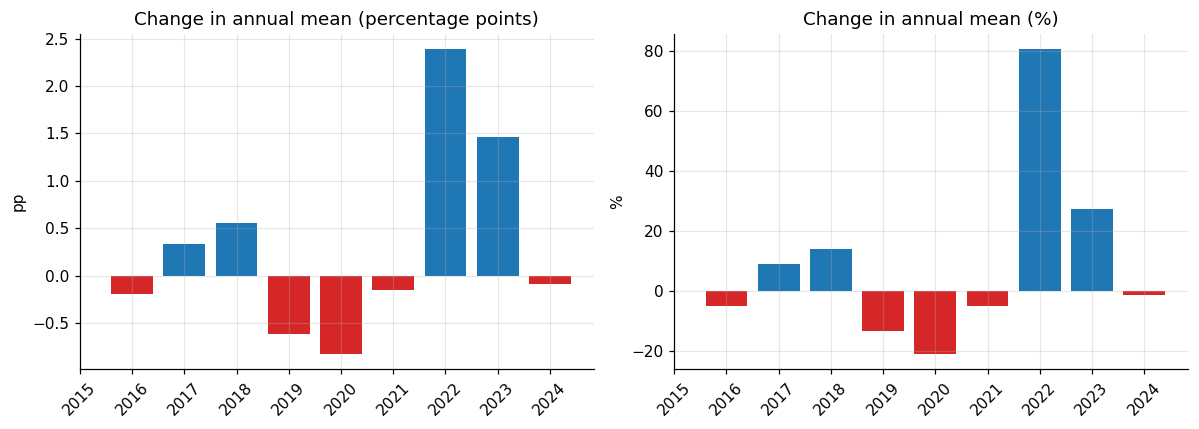

,year,mortgage_rate_mean,mortgage_rate_change,pct_change
0,2015,3.85,NaN,NaN
1,2016,3.65,-0.20,-5.12
2,2017,3.99,0.34,9.20
3,2018,4.54,0.56,13.91
4,2019,3.94,-0.61,-13.40
5,2020,3.11,-0.82,-20.93
6,2021,2.96,-0.15,-4.95
7,2022,5.34,2.39,80.66
8,2023,6.81,1.46,27.38
9,2024,6.72,-0.09,-1.26


In [18]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
colors = ["C3" if v < 0 else "C0" for v in annual["mortgage_rate_change"].fillna(0)]
axes[0].bar(annual["year"], annual["mortgage_rate_change"], color=colors)
axes[0].set(title="Change in annual mean (percentage points)", ylabel="pp")
axes[1].bar(annual["year"], annual["pct_change"], color=colors)
axes[1].set(title="Change in annual mean (%)", ylabel="%")
for a in axes: a.set_xticks(annual["year"]); a.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()
annual[["year", "mortgage_rate_mean", "mortgage_rate_change", "pct_change"]].round(2)

## Within-year spread (volatility proxy)

The annual file keeps each year's min and max, so the range (max - min) gives a simple measure of how much rates moved within the year.

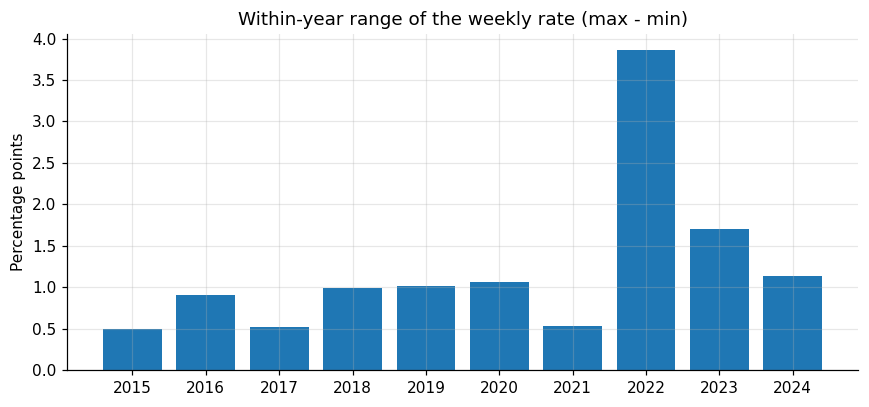

,year,mortgage_rate_min,mortgage_rate_max,range
0,2015,3.59,4.09,0.50
1,2016,3.41,4.32,0.91
2,2017,3.78,4.30,0.52
3,2018,3.95,4.94,0.99
4,2019,3.49,4.51,1.02
5,2020,2.66,3.72,1.06
6,2021,2.65,3.18,0.53
7,2022,3.22,7.08,3.86
8,2023,6.09,7.79,1.70
9,2024,6.08,7.22,1.14


In [21]:
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.bar(annual["year"], annual["range"]); ax.set_xticks(annual["year"])
ax.set(title="Within-year range of the weekly rate (max - min)", ylabel="Percentage points")
plt.tight_layout(); plt.show()
annual[["year", "mortgage_rate_min", "mortgage_rate_max", "range"]].round(2)

2022 had by far the widest within-year range (3.86 points; other years were 0.5 to 1.7), because rates climbed steadily through the year.

## Two regimes: 2015-2021 vs. 2022-2024

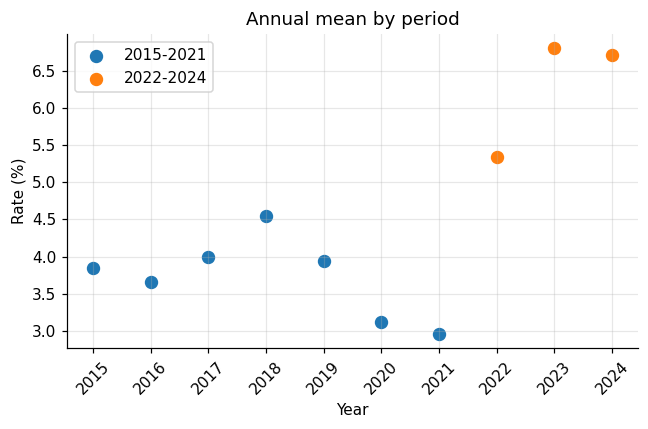

,count,mean,min,max
period,,,,
2015-2021,7,3.72,2.96,4.54
2022-2024,3,6.29,5.34,6.81


In [24]:
annual["period"] = np.where(annual["year"] <= 2021, "2015-2021", "2022-2024")
fig, ax = plt.subplots(figsize=(6, 4))
for p, g in annual.groupby("period"):
    ax.scatter(g["year"], g["mortgage_rate_mean"], s=60, label=p)
ax.set(title="Annual mean by period", xlabel="Year", ylabel="Rate (%)"); ax.set_xticks(annual["year"]); ax.tick_params(axis="x", rotation=45); ax.legend()
plt.tight_layout(); plt.show()
annual.groupby("period")["mortgage_rate_mean"].agg(["count", "mean", "min", "max"]).round(2)

The mean was about 3.7% in 2015-2021 and about 6.3% in 2022-2024. The rate fell to its lowest in 2020-2021, then jumped from 2.96% (2021) to 5.34% (2022), a rise of 2.39 points (about 81%), the largest change in the series. It rose another 1.46 points in 2023 and has since leveled off (-0.09 in 2024).

## Which annual measure to use?

In [27]:
annual["yearend_minus_mean"] = annual["mortgage_rate_yearend"] - annual["mortgage_rate_mean"]
print("Correlation, annual mean vs. year-end:", round(annual["mortgage_rate_mean"].corr(annual["mortgage_rate_yearend"]), 3))
print("Correlation, annual mean vs. median:  ", round(annual["mortgage_rate_mean"].corr(annual["mortgage_rate_median"]), 3))
annual[["year", "mortgage_rate_mean", "mortgage_rate_yearend", "yearend_minus_mean"]].round(2)

Correlation, annual mean vs. year-end: 0.955
Correlation, annual mean vs. median:   0.999


,year,mortgage_rate_mean,mortgage_rate_yearend,yearend_minus_mean
0,2015,3.85,4.01,0.16
1,2016,3.65,4.32,0.67
2,2017,3.99,3.99,0.00
3,2018,4.54,4.55,0.00
4,2019,3.94,3.74,-0.20
5,2020,3.11,2.67,-0.44
6,2021,2.96,3.11,0.15
7,2022,5.34,6.42,1.08
8,2023,6.81,6.61,-0.20
9,2024,6.72,6.85,0.13


The two measures are highly correlated (about 0.96), but they differ most in 2022 (year-end is 1.08 points above the mean) and 2016 (0.67 above). The mean represents conditions over the whole year, so it remains the primary variable. Year-end is a reasonable robustness check.